
# Glass Type Classification: Random Forest and Hyperparameter Optimization Comparison



## 1. Import Libraries


In [1]:
%pip install optuna
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models
from sklearn.ensemble import RandomForestClassifier

# Dataset loading
from sklearn.datasets import fetch_openml

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)

# Halving Search
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import (
    HalvingGridSearchCV,
    HalvingRandomSearchCV
)

# Bayesian Optimization
import optuna

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# Other utilities
import time
import warnings

warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

Note: you may need to restart the kernel to use updated packages.
All libraries imported successfully!



## 2. Load Dataset



In [2]:
# Load Glass Identification dataset using OpenML ID
glass = fetch_openml(
    data_id=41,
    as_frame=True
)

df = glass.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (214, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.51793,12.79,3.50,1.12,73.03,0.64,8.77,0.0,0.00,build wind float
1,1.51643,12.16,3.52,1.35,72.89,0.57,8.53,0.0,0.00,vehic wind float
2,1.51793,13.21,3.48,1.41,72.64,0.59,8.43,0.0,0.00,build wind float
3,1.51299,14.40,1.74,1.54,74.55,0.00,7.59,0.0,0.00,tableware
4,1.53393,12.30,0.00,1.00,70.16,0.12,16.19,0.0,0.24,build wind non-float



## 3. Data Understanding


In [3]:

# Display dataset information
df.info()

# Display statistical summary
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   RI      214 non-null    float64 
 1   Na      214 non-null    float64 
 2   Mg      214 non-null    float64 
 3   Al      214 non-null    float64 
 4   Si      214 non-null    float64 
 5   K       214 non-null    float64 
 6   Ca      214 non-null    float64 
 7   Ba      214 non-null    float64 
 8   Fe      214 non-null    float64 
 9   Type    214 non-null    category
dtypes: category(1), float64(9)
memory usage: 15.6 KB


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000


In [4]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Total Missing Values: 0


## 4. Class Distribution

Analyze the distribution of target classes to identify possible class imbalance in the dataset.

Number of samples in each class:
Type
build wind non-float    76
build wind float        70
headlamps               29
vehic wind float        17
containers              13
tableware                9
Name: count, dtype: int64


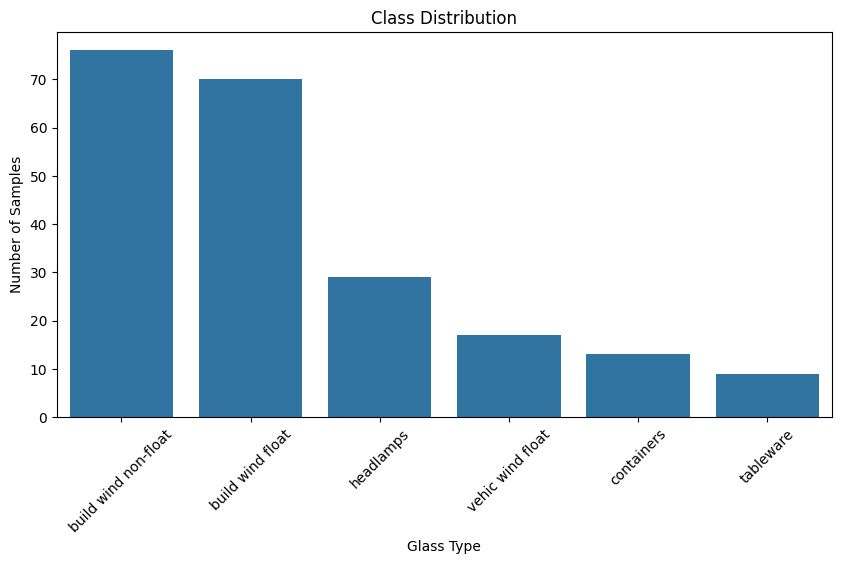

In [5]:
# Count the samples in each class
class_counts = df['Type'].value_counts()

print("Number of samples in each class:")
print(class_counts)

# Visualize class distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Type', order=class_counts.index)

plt.title("Class Distribution")
plt.xlabel("Glass Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.show()

## 5. Data Preprocessing


In [6]:
# Separate features and target
X = df.drop('Type', axis=1)
y = df['Type']

# Check data types
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes)

print("\nTarget data type:")
print(y.dtype)

Features shape: (214, 9)
Target shape: (214,)

Feature data types:
RI    float64
Na    float64
Mg    float64
Al    float64
Si    float64
K     float64
Ca    float64
Ba    float64
Fe    float64
dtype: object

Target data type:
category


## 6. Train-Test Split

 

In [7]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set shape: (171, 9)
Testing set shape: (43, 9)

Training target distribution:
Type
build wind non-float    61
build wind float        56
headlamps               23
vehic wind float        14
containers              10
tableware                7
Name: count, dtype: int64

Testing target distribution:
Type
build wind non-float    15
build wind float        14
headlamps                6
vehic wind float         3
containers               3
tableware                2
Name: count, dtype: int64


## 7. Define Random Forest Model


In [8]:
# Initialize the Random Forest classifier
rf = RandomForestClassifier(random_state=42)

print("Random Forest model initialized successfully!")

Random Forest model initialized successfully!


## 8. Define Hyperparameter Search Space

 

In [9]:
# Define the hyperparameter search space
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

print("Hyperparameter search space defined successfully!")

Hyperparameter search space defined successfully!


## 9. Grid Search

Use Grid Search to evaluate all possible combinations of hyperparameter values and identify the best configuration based on cross-validation Macro F1-score.

In [10]:
# Define cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize Grid Search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Measure execution time
start_time = time.time()

# Fit Grid Search on training data
grid_search.fit(X_train, y_train)

grid_search_time = time.time() - start_time

# Display results
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:", grid_search.best_score_)
print("Execution Time:", round(grid_search_time, 2), "seconds")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation Macro F1: 0.663549453766845
Execution Time: 62.91 seconds


### 10. Model Evaluation

Evaluate the best model selected by Grid Search on the testing set using multiple classification metrics.

In [11]:
# Predict using the best Grid Search model
y_pred_grid = grid_search.best_estimator_.predict(X_test)

# Calculate evaluation metrics
grid_accuracy = accuracy_score(y_test, y_pred_grid)
grid_precision = precision_score(y_test, y_pred_grid, average='macro', zero_division=0)
grid_recall = recall_score(y_test, y_pred_grid, average='macro', zero_division=0)
grid_f1 = f1_score(y_test, y_pred_grid, average='macro', zero_division=0)

# Display results
print("Grid Search Test Results")
print("------------------------")
print("Accuracy:", round(grid_accuracy, 4))
print("Precision:", round(grid_precision, 4))
print("Recall:", round(grid_recall, 4))
print("Macro F1-score:", round(grid_f1, 4))

Grid Search Test Results
------------------------
Accuracy: 0.8372
Precision: 0.7523
Recall: 0.7889
Macro F1-score: 0.7565


### 11. Visualization

### 11.1 Confusion Matrix

Visualize the classification results of the best Grid Search model to identify correctly and incorrectly classified samples for each class.

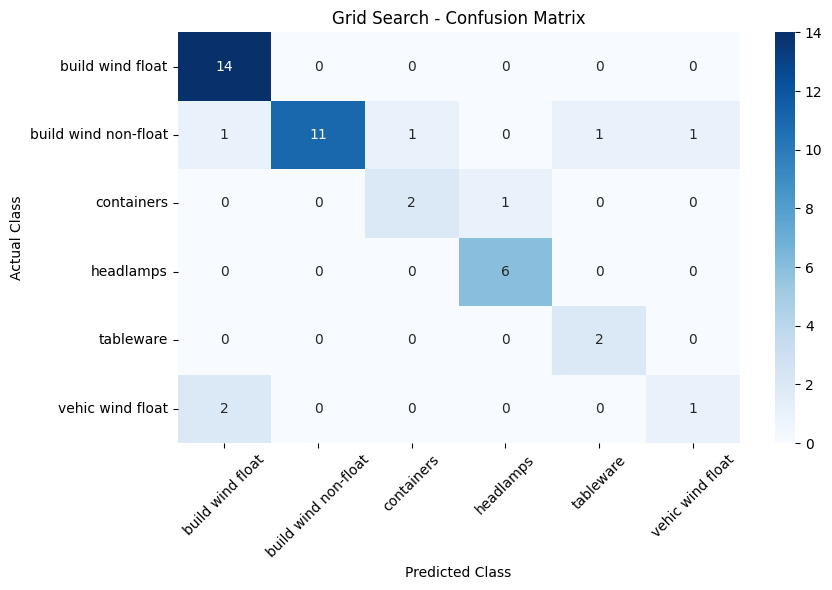

In [12]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_grid)

# Plot confusion matrix
plt.figure(figsize=(9, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=grid_search.classes_,
    yticklabels=grid_search.classes_
)

plt.title("Grid Search - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 11.2 Feature Importance

Visualize the importance of each feature in the best Random Forest model selected by Grid Search.

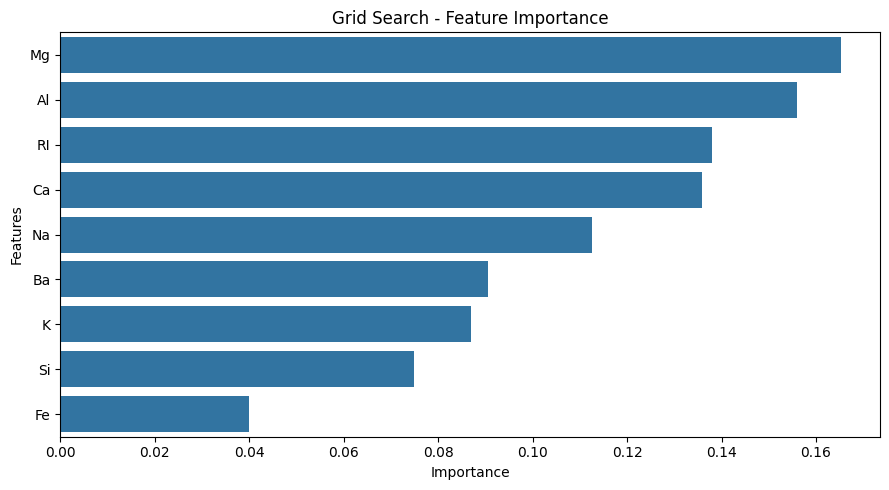

In [13]:
# Extract feature importance
feature_importance = pd.Series(
    grid_search.best_estimator_.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

# Plot feature importance
plt.figure(figsize=(9, 5))
sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title("Grid Search - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()